In [127]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pandas.api.types import is_string_dtype

from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import SMOTE
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import *
from sklearn import tree
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
import xgboost as xgb
from xgboost import XGBClassifier


import statsmodels.api as sm
import math

import warnings
warnings.filterwarnings('ignore')

pd.options.display.max_columns = None
pd.options.display.max_rows = None
np.set_printoptions(suppress = True)

In [128]:
from google.colab import drive
drive.mount('/content/drive/')

Drive already mounted at /content/drive/; to attempt to forcibly remount, call drive.mount("/content/drive/", force_remount=True).


In [129]:
df_credit_score = pd.read_csv('/content/drive/MyDrive/Capstone 2/credit_score.csv')
df_credit_score.head()

,ID,Customer_ID,Month,Name,Age,SSN,Occupation,Annual_Income,Monthly_Inhand_Salary,Num_Bank_Accounts,Num_Credit_Card,Interest_Rate,Num_of_Loan,Type_of_Loan,Delay_from_due_date,Num_of_Delayed_Payment,Changed_Credit_Limit,Num_Credit_Inquiries,Credit_Mix,Outstanding_Debt,Credit_Utilization_Ratio,Credit_History_Age,Payment_of_Min_Amount,Total_EMI_per_month,Amount_invested_monthly,Payment_Behaviour,Monthly_Balance,Credit_Score
0,0x1602,CUS_0xd40,January,Aaron Maashoh,23,821-00-0265,Scientist,19114.12,1824.843333,3,4,3,4,"Auto Loan, Credit-Builder Loan, Personal Loan,...",3,7,11.27,4.0,_,809.98,26.822620,22 Years and 1 Months,No,49.574949,80.41529543900253,High_spent_Small_value_payments,312.49408867943663,Good
1,0x1603,CUS_0xd40,February,Aaron Maashoh,23,821-00-0265,Scientist,19114.12,NaN,3,4,3,4,"Auto Loan, Credit-Builder Loan, Personal Loan,...",-1,NaN,11.27,4.0,Good,809.98,31.944960,NaN,No,49.574949,118.28022162236736,Low_spent_Large_value_payments,284.62916249607184,Good
2,0x1604,CUS_0xd40,March,Aaron Maashoh,-500,821-00-0265,Scientist,19114.12,NaN,3,4,3,4,"Auto Loan, Credit-Builder Loan, Personal Loan,...",3,7,_,4.0,Good,809.98,28.609352,22 Years and 3 Months,No,49.574949,81.699521264648,Low_spent_Medium_value_payments,331.2098628537912,Good
3,0x1605,CUS_0xd40,April,Aaron Maashoh,23,821-00-0265,Scientist,19114.12,NaN,3,4,3,4,"Auto Loan, Credit-Builder Loan, Personal Loan,...",5,4,6.27,4.0,Good,809.98,31.377862,22 Years and 4 Months,No,49.574949,199.4580743910713,Low_spent_Small_value_payments,223.45130972736786,Good
4,0x1606,CUS_0xd40,May,Aaron Maashoh,23,821-00-0265,Scientist,19114.12,1824.843333,3,4,3,4,"Auto Loan, Credit-Builder Loan, Personal Loan,...",6,NaN,11.27,4.0,Good,809.98,24.797347,22 Years and 5 Months,No,49.574949,41.420153086217326,High_spent_Medium_value_payments,341.48923103222177,Good


# Data Preprocessing and EDA

In [130]:
df_credit_score.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 28 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   ID                        100000 non-null  object 
 1   Customer_ID               100000 non-null  object 
 2   Month                     100000 non-null  object 
 3   Name                      90015 non-null   object 
 4   Age                       100000 non-null  object 
 5   SSN                       100000 non-null  object 
 6   Occupation                100000 non-null  object 
 7   Annual_Income             100000 non-null  object 
 8   Monthly_Inhand_Salary     84998 non-null   float64
 9   Num_Bank_Accounts         100000 non-null  int64  
 10  Num_Credit_Card           100000 non-null  int64  
 11  Interest_Rate             100000 non-null  int64  
 12  Num_of_Loan               100000 non-null  object 
 13  Type_of_Loan              88592 non-null   ob

We can obersve that the dataset has many missing values and the data types for some columns are incorrect too.E.g. age, annual income should be INT

In [131]:
df_credit_score.shape

(100000, 28)

# Standardizing column name

In [132]:
df_credit_score.columns = df_credit_score.columns.str.lower()

In [133]:
df_credit_score.columns

Index(['id', 'customer_id', 'month', 'name', 'age', 'ssn', 'occupation',
       'annual_income', 'monthly_inhand_salary', 'num_bank_accounts',
       'num_credit_card', 'interest_rate', 'num_of_loan', 'type_of_loan',
       'delay_from_due_date', 'num_of_delayed_payment', 'changed_credit_limit',
       'num_credit_inquiries', 'credit_mix', 'outstanding_debt',
       'credit_utilization_ratio', 'credit_history_age',
       'payment_of_min_amount', 'total_emi_per_month',
       'amount_invested_monthly', 'payment_behaviour', 'monthly_balance',
       'credit_score'],
      dtype='object')

All the column names have been converted to lower case

# Duplicating database

In [134]:
df = df_credit_score.copy()

In [135]:
df.head()

,id,customer_id,month,name,age,ssn,occupation,annual_income,monthly_inhand_salary,num_bank_accounts,num_credit_card,interest_rate,num_of_loan,type_of_loan,delay_from_due_date,num_of_delayed_payment,changed_credit_limit,num_credit_inquiries,credit_mix,outstanding_debt,credit_utilization_ratio,credit_history_age,payment_of_min_amount,total_emi_per_month,amount_invested_monthly,payment_behaviour,monthly_balance,credit_score
0,0x1602,CUS_0xd40,January,Aaron Maashoh,23,821-00-0265,Scientist,19114.12,1824.843333,3,4,3,4,"Auto Loan, Credit-Builder Loan, Personal Loan,...",3,7,11.27,4.0,_,809.98,26.822620,22 Years and 1 Months,No,49.574949,80.41529543900253,High_spent_Small_value_payments,312.49408867943663,Good
1,0x1603,CUS_0xd40,February,Aaron Maashoh,23,821-00-0265,Scientist,19114.12,NaN,3,4,3,4,"Auto Loan, Credit-Builder Loan, Personal Loan,...",-1,NaN,11.27,4.0,Good,809.98,31.944960,NaN,No,49.574949,118.28022162236736,Low_spent_Large_value_payments,284.62916249607184,Good
2,0x1604,CUS_0xd40,March,Aaron Maashoh,-500,821-00-0265,Scientist,19114.12,NaN,3,4,3,4,"Auto Loan, Credit-Builder Loan, Personal Loan,...",3,7,_,4.0,Good,809.98,28.609352,22 Years and 3 Months,No,49.574949,81.699521264648,Low_spent_Medium_value_payments,331.2098628537912,Good
3,0x1605,CUS_0xd40,April,Aaron Maashoh,23,821-00-0265,Scientist,19114.12,NaN,3,4,3,4,"Auto Loan, Credit-Builder Loan, Personal Loan,...",5,4,6.27,4.0,Good,809.98,31.377862,22 Years and 4 Months,No,49.574949,199.4580743910713,Low_spent_Small_value_payments,223.45130972736786,Good
4,0x1606,CUS_0xd40,May,Aaron Maashoh,23,821-00-0265,Scientist,19114.12,1824.843333,3,4,3,4,"Auto Loan, Credit-Builder Loan, Personal Loan,...",6,NaN,11.27,4.0,Good,809.98,24.797347,22 Years and 5 Months,No,49.574949,41.420153086217326,High_spent_Medium_value_payments,341.48923103222177,Good


Creating a copy of the database so as to not alternate or cause data loss to the original database of the company

# Understanding the dataset

Period of time for which the data is available:

In [136]:
df['month'].nunique()
df['month'].unique()

array(['January', 'February', 'March', 'April', 'May', 'June', 'July',
       'August'], dtype=object)

The dataset maps out historical data of a year from January to August, having a total of 8 unique months.

In [137]:
df['month'].value_counts()

,count
month,
January,12500
February,12500
March,12500
April,12500
May,12500
June,12500
July,12500
August,12500


In [138]:
df['customer_id'].nunique()

12500

Each month has 12500 data entries and the total number of customers is also 12500. We need to ensure these 12500 entries correspond to the same 8 months for each customer. We can do this by counting number of unique months for each customer

In [139]:
df.groupby('customer_id')['month'].nunique().value_counts()

,count
month,
8,12500


This verifies that there is no data leakage or data quality issues. If a month had fewer than 12500 rows that means there is data missing or perphas some of it was lost during importing data. On the contrary, if a month had more than 12500 entries it could have meant that there is duplicate/overlapping data for a customer.

# Verifying if the data is chronologically sequential

We must verify if the data is present in a chronoligcally sequential pattern and that there are no time gaps for any customers. For this we'll use credit_history_age column because this feature tracks how long a customer has had credit.

The difference between two consecutive months for each customer should always be 1 because time moves forward linearly. The credit age must increase exactly by 1 month because a customer must have credit in Month 1 and then in Month 2 to signify exactly 1 month of real time has passed.

If we compute the difference between two consecutive rows for a customer and get a number other than 1, it signals data quality issues:

Difference > 1 (e.g., 3): There is a data gap. The customer has missing records (e.g., we have data for January and May, but skipped February, March, and April).

Difference = 0: There is a duplicate record error. The same customer has two entries representing the exact same month.

Difference < 0 (Negative): The data rows are shuffled out of order, or a completely different customer's data has leaked into the sequence.

In [140]:
temp_df = df['credit_history_age'].str.extract('(?P<Years>\d+) Years and (?P<Months>\d+) Months').astype(float)
temp_df['customer_id'] = df['customer_id']
temp_df['total_months'] = temp_df['Years'] * 12 + temp_df['Months'] #This specific line of code converts a time duration from years and months into a single, uniform unit: total months.
temp_df.groupby('customer_id')['total_months'].transform(pd.Series.diff).unique()

array([nan,  1.])

We can confirm that each customer has no missing or duplicated data. The rows aren't shuffled out, interpreting the sequence

# Credit Score check

We should check if the customer's credit score varies from month to month

In [141]:
df.groupby('customer_id')['credit_score'].nunique().value_counts()

,count
credit_score,
2,7262
1,5208
3,30


The customer credit score varies from month to month. It is perfectly normal for the credit score to stay the same or vary. This means depending upon any current months situation and past history as well, a customer can be classified in different credit score brackets.



In [142]:
# age validation
#data stripping/cleaning
# null values
# outliers

# Data Pre Processing

Dropping unique identifier columns like customer_id, SSN because these unique identifiers are not required for ML models and often lead to overfitting as model might memorize each unique ID instead of learning patterns

In [143]:
df.columns

Index(['id', 'customer_id', 'month', 'name', 'age', 'ssn', 'occupation',
       'annual_income', 'monthly_inhand_salary', 'num_bank_accounts',
       'num_credit_card', 'interest_rate', 'num_of_loan', 'type_of_loan',
       'delay_from_due_date', 'num_of_delayed_payment', 'changed_credit_limit',
       'num_credit_inquiries', 'credit_mix', 'outstanding_debt',
       'credit_utilization_ratio', 'credit_history_age',
       'payment_of_min_amount', 'total_emi_per_month',
       'amount_invested_monthly', 'payment_behaviour', 'monthly_balance',
       'credit_score'],
      dtype='object')

In [144]:
df = df.drop(['id','customer_id', 'name','ssn'], axis =1)

In [145]:
df.head()

,month,age,occupation,annual_income,monthly_inhand_salary,num_bank_accounts,num_credit_card,interest_rate,num_of_loan,type_of_loan,delay_from_due_date,num_of_delayed_payment,changed_credit_limit,num_credit_inquiries,credit_mix,outstanding_debt,credit_utilization_ratio,credit_history_age,payment_of_min_amount,total_emi_per_month,amount_invested_monthly,payment_behaviour,monthly_balance,credit_score
0,January,23,Scientist,19114.12,1824.843333,3,4,3,4,"Auto Loan, Credit-Builder Loan, Personal Loan,...",3,7,11.27,4.0,_,809.98,26.822620,22 Years and 1 Months,No,49.574949,80.41529543900253,High_spent_Small_value_payments,312.49408867943663,Good
1,February,23,Scientist,19114.12,NaN,3,4,3,4,"Auto Loan, Credit-Builder Loan, Personal Loan,...",-1,NaN,11.27,4.0,Good,809.98,31.944960,NaN,No,49.574949,118.28022162236736,Low_spent_Large_value_payments,284.62916249607184,Good
2,March,-500,Scientist,19114.12,NaN,3,4,3,4,"Auto Loan, Credit-Builder Loan, Personal Loan,...",3,7,_,4.0,Good,809.98,28.609352,22 Years and 3 Months,No,49.574949,81.699521264648,Low_spent_Medium_value_payments,331.2098628537912,Good
3,April,23,Scientist,19114.12,NaN,3,4,3,4,"Auto Loan, Credit-Builder Loan, Personal Loan,...",5,4,6.27,4.0,Good,809.98,31.377862,22 Years and 4 Months,No,49.574949,199.4580743910713,Low_spent_Small_value_payments,223.45130972736786,Good
4,May,23,Scientist,19114.12,1824.843333,3,4,3,4,"Auto Loan, Credit-Builder Loan, Personal Loan,...",6,NaN,11.27,4.0,Good,809.98,24.797347,22 Years and 5 Months,No,49.574949,41.420153086217326,High_spent_Medium_value_payments,341.48923103222177,Good


Stripping columns of special characters: Stripping Dataset of incoherent values like special characters !@9#%8 in columns like payment_behaviour, unrequired _ (39628.99_) in income column etc

In [146]:
df['age'][~df['age'].str.isnumeric()].unique() #extracting non numeric textual data

array(['-500', '28_', '34_', '30_', '24_', '33_', '35_', '31_', '40_',
       '37_', '54_', '21_', '20_', '43_', '38_', '18_', '2111_', '46_',
       '16_', '19_', '47_', '53_', '25_', '27_', '55_', '42_', '48_',
       '49_', '50_', '32_', '22_', '17_', '29_', '15_', '51_', '26_',
       '39_', '14_', '36_', '44_', '7670_', '45_', '23_', '41_', '52_',
       '733_', '5769_', '4383_', '56_', '2650_', '3307_', '6962_',
       '5589_', '6556_', '1447_', '8153_', '3834_', '6744_', '6471_',
       '7723_', '7640_', '6408_', '3502_', '7316_', '1102_', '8669_',
       '2463_', '6666_', '3055_', '1248_', '2220_', '2159_', '4583_',
       '3988_', '2155_', '6770_', '1843_', '1367_', '3742_', '2171_',
       '5109_', '3984_', '2474_', '5046_', '7715_', '2329_', '707_',
       '844_', '2756_', '2037_', '902_', '8523_', '3640_', '3998_',
       '3712_', '2097_', '8348_', '5373_', '3291_', '2994_', '3339_',
       '2812_', '3578_', '3564_', '1794_', '737_', '4301_', '2846_',
       '2373_', '1188_

In [147]:
df['age'] = df['age'].str.replace('_', '')

In [148]:
df['age'][~df['age'].str.isnumeric()].unique()

array(['-500'], dtype=object)

Negative values like -500, -1, -999 are often used as placeholder values to indicate missing data. We'll treat it later

# Checking Data types

In [149]:
df.dtypes

,0
month,object
age,object
occupation,object
annual_income,object
monthly_inhand_salary,float64
num_bank_accounts,int64
num_credit_card,int64
interest_rate,int64
num_of_loan,object
type_of_loan,object


Many features have incorrect data types which need to be corrected. The correct type should be:
age = int
occupation needs to be encoded
annual_income = float
interest_rate = float
num_of_loan = int
type_of_loan should be encoded
num_of_delayed_payment = int
credit_mix should be encoded
outstanding_debt = float
payment_of_min_amount should be encoded
amount_invested_monthly = float
payment_behaviour = should be encoded
monthly_balance = float
Since the data has missing values we'll use df.convert_dtypes

# Data Cleaning

1. Age

In [150]:
df['age'] = df['age'].astype(int)

# 2. Annual income

Annual Income should be positive and float in nature

In [151]:
df['annual_income'][~df['annual_income'].str.isnumeric()].unique()

array(['19114.12', '34847.84', '34847.84_', ..., '20002.88', '39628.99',
       '39628.99_'], dtype=object)

In [152]:
df['annual_income'] = df['annual_income'].str.replace('_', '')

In [153]:
df['annual_income'][~df['annual_income'].str.isnumeric()].unique()

array(['19114.12', '34847.84', '143162.64', ..., '37188.1', '20002.88',
       '39628.99'], dtype=object)

special chars have been treated

Changing type to float

In [154]:
df['annual_income'] = df['annual_income'].astype(float)

In [155]:
df['num_of_loan'][~df['num_of_loan'].str.isnumeric()].unique()

array(['-100', '0_', '3_', '2_', '5_', '8_', '9_', '4_', '7_', '1_', '6_',
       '597_', '92_', '1347_', '1185_', '235_', '1459_', '1320_', '630_',
       '359_', '1225_', '131_', '1311_', '1129_', '785_', '143_', '1131_',
       '27_', '1171_', '227_', '378_', '1219_', '527_', '1027_', '696_',
       '1132_'], dtype=object)

# 3. Num of loan

Values in num of loan should be non negative integers

In [156]:
df['num_of_loan'] = df['num_of_loan'].str.replace('_', '')

In [157]:
df['num_of_loan'] = df['num_of_loan'].astype(int)

# 4. Number of delayed payments

Number of delayed payments should be non negative integers. The column has null values so we'll first need to create a temporary variable to non null values

In [158]:
temp_series = df['num_of_delayed_payment'][df['num_of_delayed_payment'].notnull()]

In [159]:
temp_series[~temp_series.str.isnumeric()].unique()

array(['8_', '-1', '3_', '2_', '13_', '14_', '12_', '22_', '4_', '11_',
       '21_', '10_', '183_', '9_', '19_', '24_', '17_', '23_', '20_',
       '-3', '6_', '1_', '16_', '-2', '15_', '26_', '18_', '5_', '25_',
       '7_', '0_', '2569_', '27_', '663_', '-2_', '28_', '-1_', '1323_',
       '2794_', '2219_', '758_', '-3_', '848_', '2237_', '3097_', '2566_',
       '3840_', '2278_', '1087_', '1295_', '3861_', '2142_', '1473_',
       '3920_'], dtype=object)

In [160]:
df['num_of_delayed_payment']= df['num_of_delayed_payment'].str.replace('_', '')

In [161]:
df['num_of_delayed_payment']= df['num_of_delayed_payment'].astype(float)

# 5. Outstanding Debt

In [162]:
df['outstanding_debt'][~df['outstanding_debt'].str.isnumeric()].unique()

array(['809.98', '605.03', '1303.01', ..., '3571.7_', '3571.7', '502.38'],
      dtype=object)

In [163]:
df['outstanding_debt'] = df['outstanding_debt'].str.replace('_', '').astype(float)

# 6. amount_invested monthly

Amount invested monthly should be non negative float but the column has null values

In [164]:
temp = df['amount_invested_monthly'][df['amount_invested_monthly'].notnull()]

In [165]:
temp[~temp.str.fullmatch('([0-9]*[.])?[0-9]+')].unique()

array(['__10000__'], dtype=object)

In [166]:
df['amount_invested_monthly'] = df['amount_invested_monthly'].str.replace('_', '').astype(float)

#7. Payment Behaviour

In [167]:
df['payment_behaviour'].unique()

array(['High_spent_Small_value_payments',
       'Low_spent_Large_value_payments',
       'Low_spent_Medium_value_payments',
       'Low_spent_Small_value_payments',
       'High_spent_Medium_value_payments', '!@9#%8',
       'High_spent_Large_value_payments'], dtype=object)

Values like !@9#%8 are actually incorrect data and should be treated as null values

In [168]:
df['payment_behaviour'][df['payment_behaviour'] == '!@9#%8'] = np.nan

# 8. Monthly Balance

In [169]:
temp_1 = df['monthly_balance'][df['monthly_balance'].notnull()]

In [170]:
temp_1[temp_1.str.fullmatch('[+-]*([0-9]*[.])?[0-9]+') == False].unique()

array(['__-333333333333333333333333333__'], dtype=object)

In [171]:
df['monthly_balance'] = df['monthly_balance'].str.replace('_', '').astype(float)

However, the value -3333333 is a placeholder value and should be converted to null value

In [172]:
df['monthly_balance'][df['monthly_balance'] == '-333333333333333333333333333'] == np.nan

,monthly_balance


In [173]:
df.dtypes

,0
month,object
age,int64
occupation,object
annual_income,float64
monthly_inhand_salary,float64
num_bank_accounts,int64
num_credit_card,int64
interest_rate,int64
num_of_loan,int64
type_of_loan,object


All the data types have been successfully changed

# 9. occupation

In [174]:
df['occupation'].unique()

array(['Scientist', '_______', 'Teacher', 'Engineer', 'Entrepreneur',
       'Developer', 'Lawyer', 'Media_Manager', 'Doctor', 'Journalist',
       'Manager', 'Accountant', 'Musician', 'Mechanic', 'Writer',
       'Architect'], dtype=object)

Here the blank spaces could be categorized as unemployed

In [175]:
df['occupation'] = df['occupation'].str.replace('_______', 'unemployed')

In [176]:
df['occupation'].unique()

array(['Scientist', 'unemployed', 'Teacher', 'Engineer', 'Entrepreneur',
       'Developer', 'Lawyer', 'Media_Manager', 'Doctor', 'Journalist',
       'Manager', 'Accountant', 'Musician', 'Mechanic', 'Writer',
       'Architect'], dtype=object)

# 10. type of loan

In [177]:
df['type_of_loan'].unique()

array(['Auto Loan, Credit-Builder Loan, Personal Loan, and Home Equity Loan',
       'Credit-Builder Loan', 'Auto Loan, Auto Loan, and Not Specified',
       ..., 'Home Equity Loan, Auto Loan, Auto Loan, and Auto Loan',
       'Payday Loan, Student Loan, Mortgage Loan, and Not Specified',
       'Personal Loan, Auto Loan, Mortgage Loan, Student Loan, and Student Loan'],
      dtype=object)

# 11. Changed credit limit

In [178]:
df['changed_credit_limit'].unique()

array(['11.27', '_', '6.27', ..., '17.509999999999998', '25.16', '21.17'],
      dtype=object)

In [179]:
df['changed_credit_limit'][df['changed_credit_limit'] == '_'] = np.nan

In [180]:
df['changed_credit_limit'] = df['changed_credit_limit'].astype(float)

# 12. Payment of min amount

In [181]:
df['payment_of_min_amount'].unique()

array(['No', 'NM', 'Yes'], dtype=object)

Here NM are actually null values

In [182]:
df['payment_of_min_amount'][df['payment_of_min_amount']== 'NM'] = np.nan

# 13. Credit mix

In [183]:
df['credit_mix'].unique()

array(['_', 'Good', 'Standard', 'Bad'], dtype=object)

In [184]:
df['credit_mix'][df['credit_mix'] == '_'] = np.nan

# Descriptive Analysis

In [185]:
df.describe()

,age,annual_income,monthly_inhand_salary,num_bank_accounts,num_credit_card,interest_rate,num_of_loan,delay_from_due_date,num_of_delayed_payment,changed_credit_limit,num_credit_inquiries,outstanding_debt,credit_utilization_ratio,total_emi_per_month,amount_invested_monthly,monthly_balance
count,100000.000000,1.000000e+05,84998.000000,100000.000000,100000.00000,100000.000000,100000.000000,100000.000000,92998.000000,97909.000000,98035.000000,100000.000000,100000.000000,100000.000000,95521.000000,9.713200e+04
mean,110.649700,1.764157e+05,4194.170850,17.091280,22.47443,72.466040,3.009960,21.068780,30.923342,10.389025,27.754251,1426.220376,32.285173,1403.118217,637.412998,-3.088580e+22
std,686.244717,1.429618e+06,3183.686167,117.404834,129.05741,466.422621,62.647879,14.860104,226.031892,6.789496,193.177339,1155.129026,5.116875,8306.041270,2043.319327,3.208492e+24
min,-500.000000,7.005930e+03,303.645417,-1.000000,0.00000,1.000000,-100.000000,-5.000000,-3.000000,-6.490000,0.000000,0.230000,20.000000,0.000000,0.000000,-3.333333e+26
25%,24.000000,1.945750e+04,1625.568229,3.000000,4.00000,8.000000,1.000000,10.000000,9.000000,5.320000,3.000000,566.072500,28.052567,30.306660,74.534002,2.699858e+02
50%,33.000000,3.757861e+04,3093.745000,6.000000,5.00000,13.000000,3.000000,18.000000,14.000000,9.400000,6.000000,1166.155000,32.305784,69.249473,135.925682,3.364493e+02
75%,42.000000,7.279092e+04,5957.448333,7.000000,7.00000,20.000000,5.000000,28.000000,18.000000,14.870000,9.000000,1945.962500,36.496663,161.224249,265.731733,4.696405e+02
max,8698.000000,2.419806e+07,15204.633333,1798.000000,1499.00000,5797.000000,1496.000000,67.000000,4397.000000,36.970000,2597.000000,4998.070000,50.000000,82331.000000,10000.000000,1.602041e+03


There are many placeholder values like -500, -1 -100 in features like age, num_bank_accounts, num_of_loan, delay_from_due_date, num_of_delayed_payment. These are not real values but rather missing values which need to be treated

There are outliers in age and other features

# Handling Missing Values

Negative values like -500, -1, -999 are often used as placeholder values to indicate missing data. Therefore, we'll input -values with NaN

In [186]:
exclude_cols = ['delay_from_due_date', 'monthly_balance'] #excluding these columns because a negative number in delay_from_due_date means an early repayment and a negative number in monthly balance means a credit overdue
cols = df.select_dtypes(include = [np.number]).columns.difference(exclude_cols)
df[cols] = df[cols].mask(df[cols] < 0, np.nan)

In [187]:
df.describe()

,age,annual_income,monthly_inhand_salary,num_bank_accounts,num_credit_card,interest_rate,num_of_loan,delay_from_due_date,num_of_delayed_payment,changed_credit_limit,num_credit_inquiries,outstanding_debt,credit_utilization_ratio,total_emi_per_month,amount_invested_monthly,monthly_balance
count,99114.000000,1.000000e+05,84998.000000,99979.000000,100000.00000,100000.000000,96124.000000,100000.000000,92354.000000,96323.000000,98035.000000,100000.000000,100000.000000,100000.000000,95521.000000,9.713200e+04
mean,116.108421,1.764157e+05,4194.170850,17.095080,22.47443,72.466040,7.163622,21.068780,31.150519,10.599042,27.754251,1426.220376,32.285173,1403.118217,637.412998,-3.088580e+22
std,686.861274,1.429618e+06,3183.686167,117.416871,129.05741,466.422621,60.314923,14.860104,226.802173,6.639966,193.177339,1155.129026,5.116875,8306.041270,2043.319327,3.208492e+24
min,14.000000,7.005930e+03,303.645417,0.000000,0.00000,1.000000,0.000000,-5.000000,0.000000,0.000000,0.000000,0.230000,20.000000,0.000000,0.000000,-3.333333e+26
25%,25.000000,1.945750e+04,1625.568229,3.000000,4.00000,8.000000,2.000000,10.000000,9.000000,5.570000,3.000000,566.072500,28.052567,30.306660,74.534002,2.699858e+02
50%,33.000000,3.757861e+04,3093.745000,6.000000,5.00000,13.000000,3.000000,18.000000,14.000000,9.520000,6.000000,1166.155000,32.305784,69.249473,135.925682,3.364493e+02
75%,42.000000,7.279092e+04,5957.448333,7.000000,7.00000,20.000000,5.000000,28.000000,18.000000,15.010000,9.000000,1945.962500,36.496663,161.224249,265.731733,4.696405e+02
max,8698.000000,2.419806e+07,15204.633333,1798.000000,1499.00000,5797.000000,1496.000000,67.000000,4397.000000,36.970000,2597.000000,4998.070000,50.000000,82331.000000,10000.000000,1.602041e+03


In [188]:
df.isnull().sum()

,0
month,0
age,886
occupation,0
annual_income,0
monthly_inhand_salary,15002
num_bank_accounts,21
num_credit_card,0
interest_rate,0
num_of_loan,3876
type_of_loan,11408


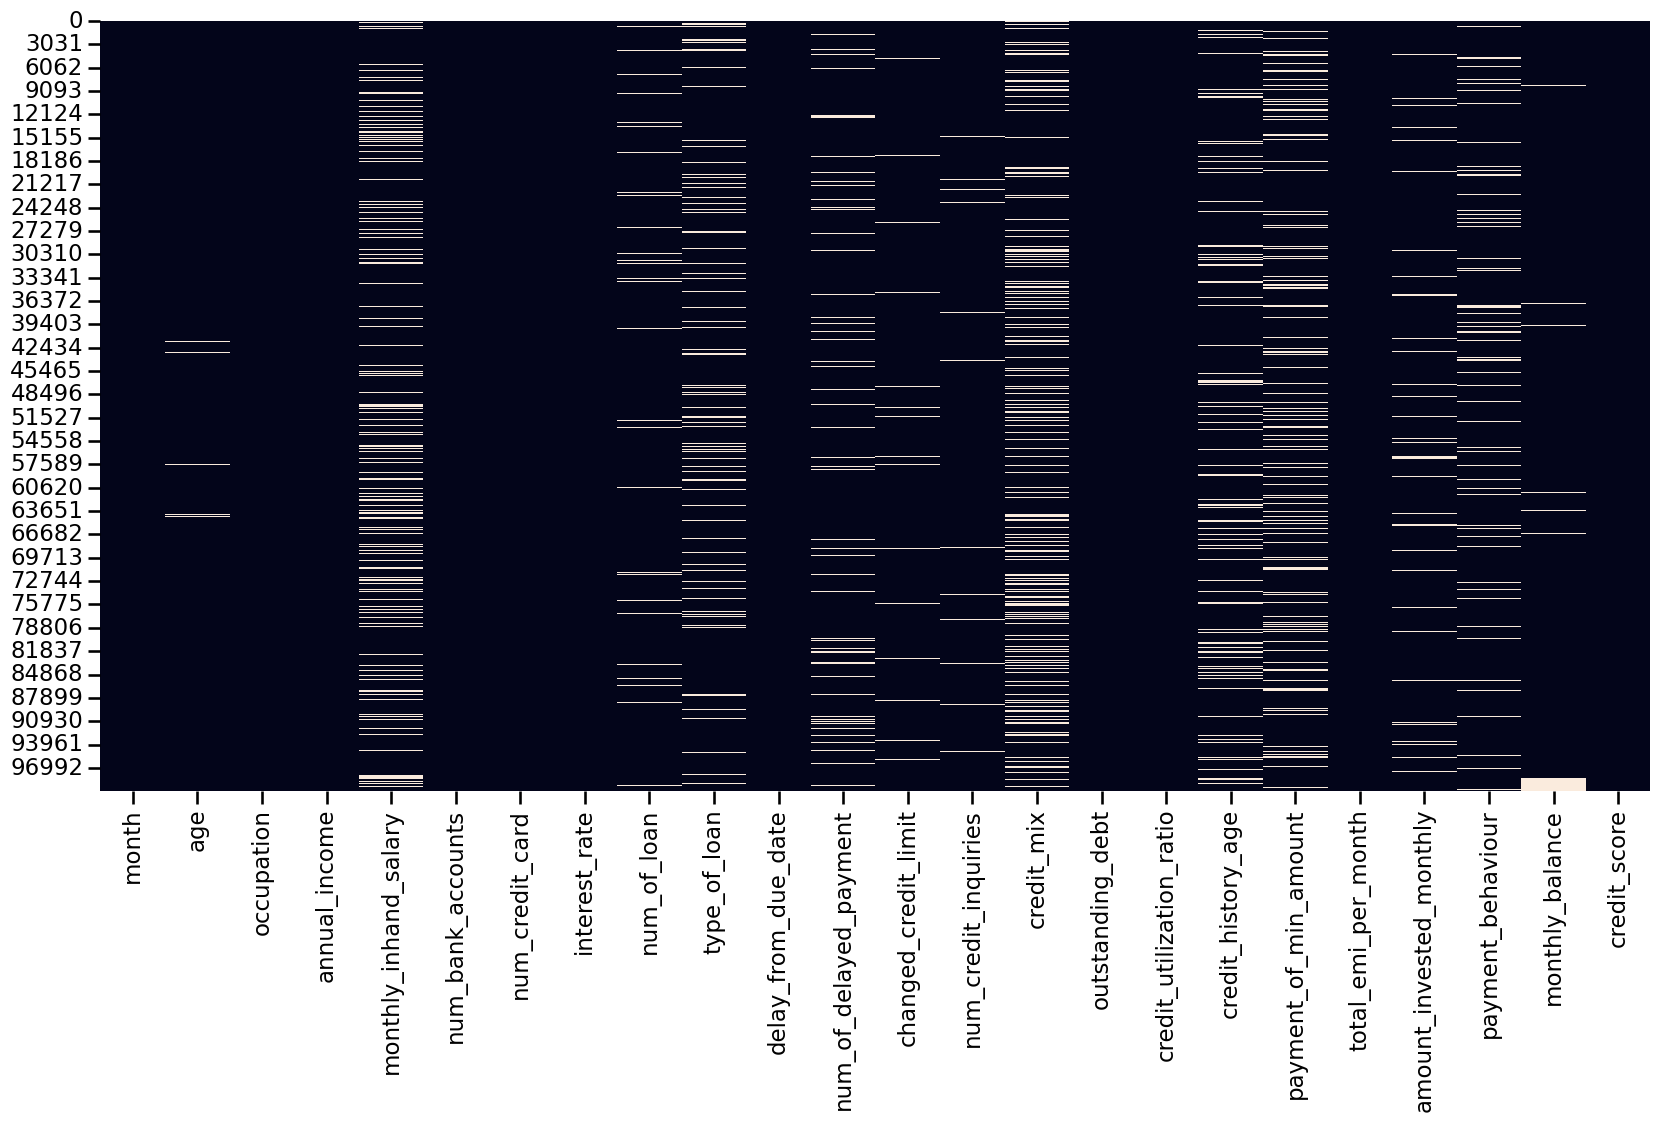

In [189]:
plt.figure(figsize=(20,10))
sns.heatmap(df.isnull(), cbar = False)
plt.show()

missing values in num_of_loan, type_of_loan, num_of_delayed_payment, credit_history_age, and amount_of_min_amount often occur in the exact same rows simultaneously. Columns like num_bank_accounts, num_credit_card, and outstanding_debt are completely solid dark blue. This means every single row in this dataset belongs to an established customer who already has active bank accounts, active credit cards, and active debt.Because there are no "empty" customer profiles anywhere in this dataset, filling any of these missing values with 0 will mathematically corrupt your data.

Converting text data in credit history column to numerical

In [190]:
# 1. Extract the number for Years and multiply by 12
years = df['credit_history_age'].str.extract(r'(\d+)\s*Years').astype(float).fillna(0) * 12

#2. Extracting number of months
months = df['credit_history_age'].str.extract(r'(\d+)\s*Months').astype(float).fillna(0)

#joining the variables to get total months while also preserving original missing entries (NaNs)

df['credit_history_age'] = years + months
df.loc[df['credit_history_age'] == 0, 'credit_history_age'] = np.nan

In [191]:
df['credit_history_age'].head(2)

,credit_history_age
0,265.0
1,NaN


Column has been converting successfully

In [192]:
#Handling columns heavily tied to overall credit profile (using group medians). People with the same number of cards generally have similar ages and payment histories

df['credit_history_age'] = df.groupby('num_credit_card')['credit_history_age'].transform(lambda x: x.fillna(x.median()))
df['num_of_delayed_payment'] = df.groupby('num_credit_card')['num_of_delayed_payment'].transform(lambda x: x.fillna(x.median()))

# Handling monthly dynamic financial metrics (using median grouped by monthly income brackets)
# Income directly dictates how much someone can save, invest, or make as an EMI payment
df['monthly_income_q'] = pd.qcut(df['annual_income'], q = 10, labels = False, duplicates = 'drop')
income_cols = ['monthly_inhand_salary', 'total_emi_per_month', 'amount_invested_monthly', 'monthly_balance']
for col in income_cols:
  if col in df.columns:
    df[col] = df.groupby('monthly_income_q')[col].transform(lambda x: x.fillna(x.median()))

# Handling standalone credit/loan metrics (using global column medians)

global_median_cols = ['num_of_loan', 'num_credit_inquiries']
for col in global_median_cols:
  df[col] = df[col].fillna(df[col].median())

# Cleaning up categorical/text gaps using moode

df['type_of_loan'] = df['type_of_loan'].fillna(df['type_of_loan'].mode()[0])

# Dropping the temporary income bracket column used for cleaning
df = df.drop(columns = ['monthly_income_q'])

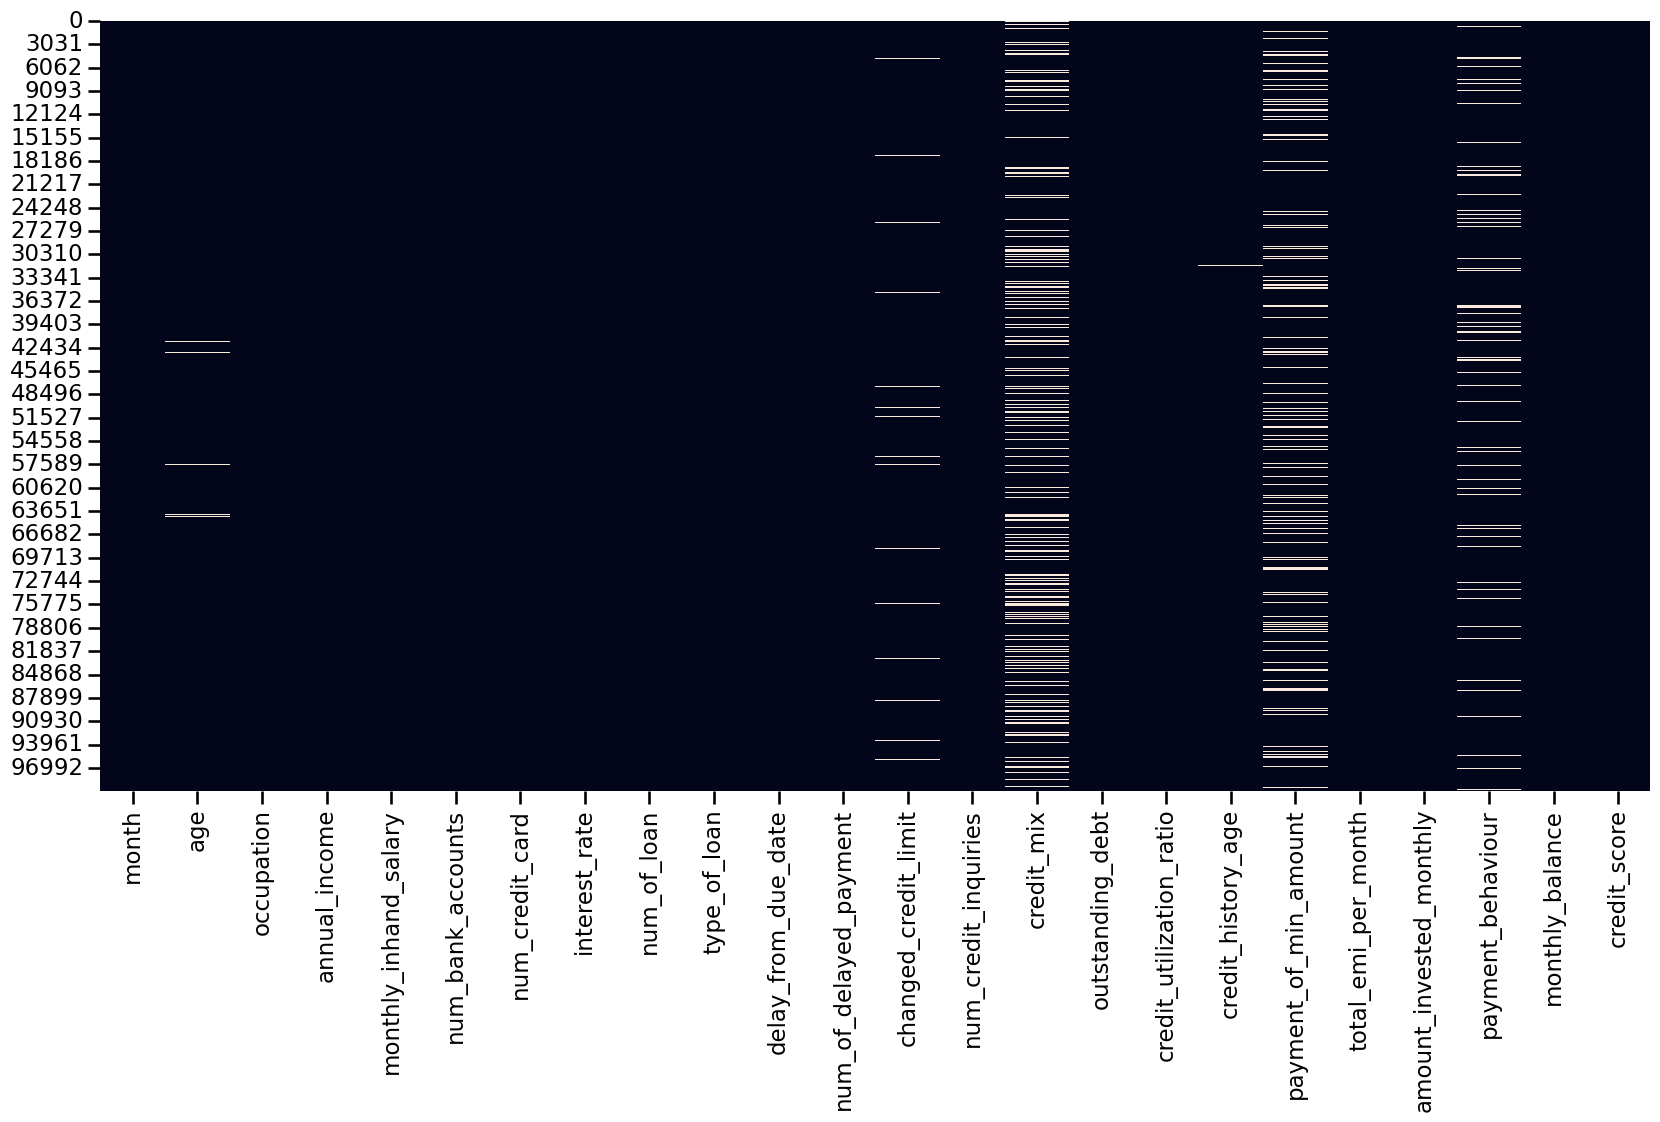

In [193]:
plt.figure(figsize = (20,10))
sns.heatmap(df.isnull(), cbar = False)
plt.show()

# Null values in age   

The dataset had many place holder values like -500, -1 in age column which we had replaced with NaN values. However, the customers have rows tracking their data over 8 months. The real age of each customer is recorded in one month and not in another.

In [194]:
# adding customer_id column back to group age by customer_id
df = df.merge(df_credit_score[['customer_id']], left_index = True, right_index = True, how = 'left')

#treating null values
df['age'] = df.groupby('customer_id')['age'].transform(lambda x: x.fillna(x.median()))


# Null values in payment_of_min_amount

In [195]:
df['payment_of_min_amount'].unique()

array(['No', nan, 'Yes'], dtype=object)

# Null values in payment behaviour

In [196]:
df['payment_behaviour'].unique()

array(['High_spent_Small_value_payments',
       'Low_spent_Large_value_payments',
       'Low_spent_Medium_value_payments',
       'Low_spent_Small_value_payments',
       'High_spent_Medium_value_payments', nan,
       'High_spent_Large_value_payments'], dtype=object)

We need to perform feature engineering before treating the null values because the payment_behaviour feature consists of two different data. Values high vs low spent signify the spending habits where as spent indicates the payment method

In [197]:
# Cleaning up text anamolies and white spaces and converting Nan values to true nulls

df['payment_behaviour'] = df['payment_behaviour'].astype(str).str.strip()
df['payment_behaviour'] = df['payment_behaviour'].replace({'nan': np.nan, 'none': np.nan})

# Extract Spending habits (high vs low)

df['spending_level'] = df['payment_behaviour'].apply(lambda x: 'high' if pd.notna(x) and 'High_spent' in x else ('low' if pd.notna(x) and 'Low_spent' in x else np.nan))

# Extracting payment method
df['payment_method'] = df['payment_behaviour'].apply(lambda x: x.split('_spent_')[-1] if pd.notna(x) else np.nan)

#filling missing rows with mode

df['spending_level'] = df['spending_level'].fillna(df['spending_level'].mode()[0])
df['payment_method'] = df['payment_method'].fillna(df['payment_method'].mode()[0])

#dropping column payment_behaviour

df = df.drop(columns = ['payment_behaviour'])


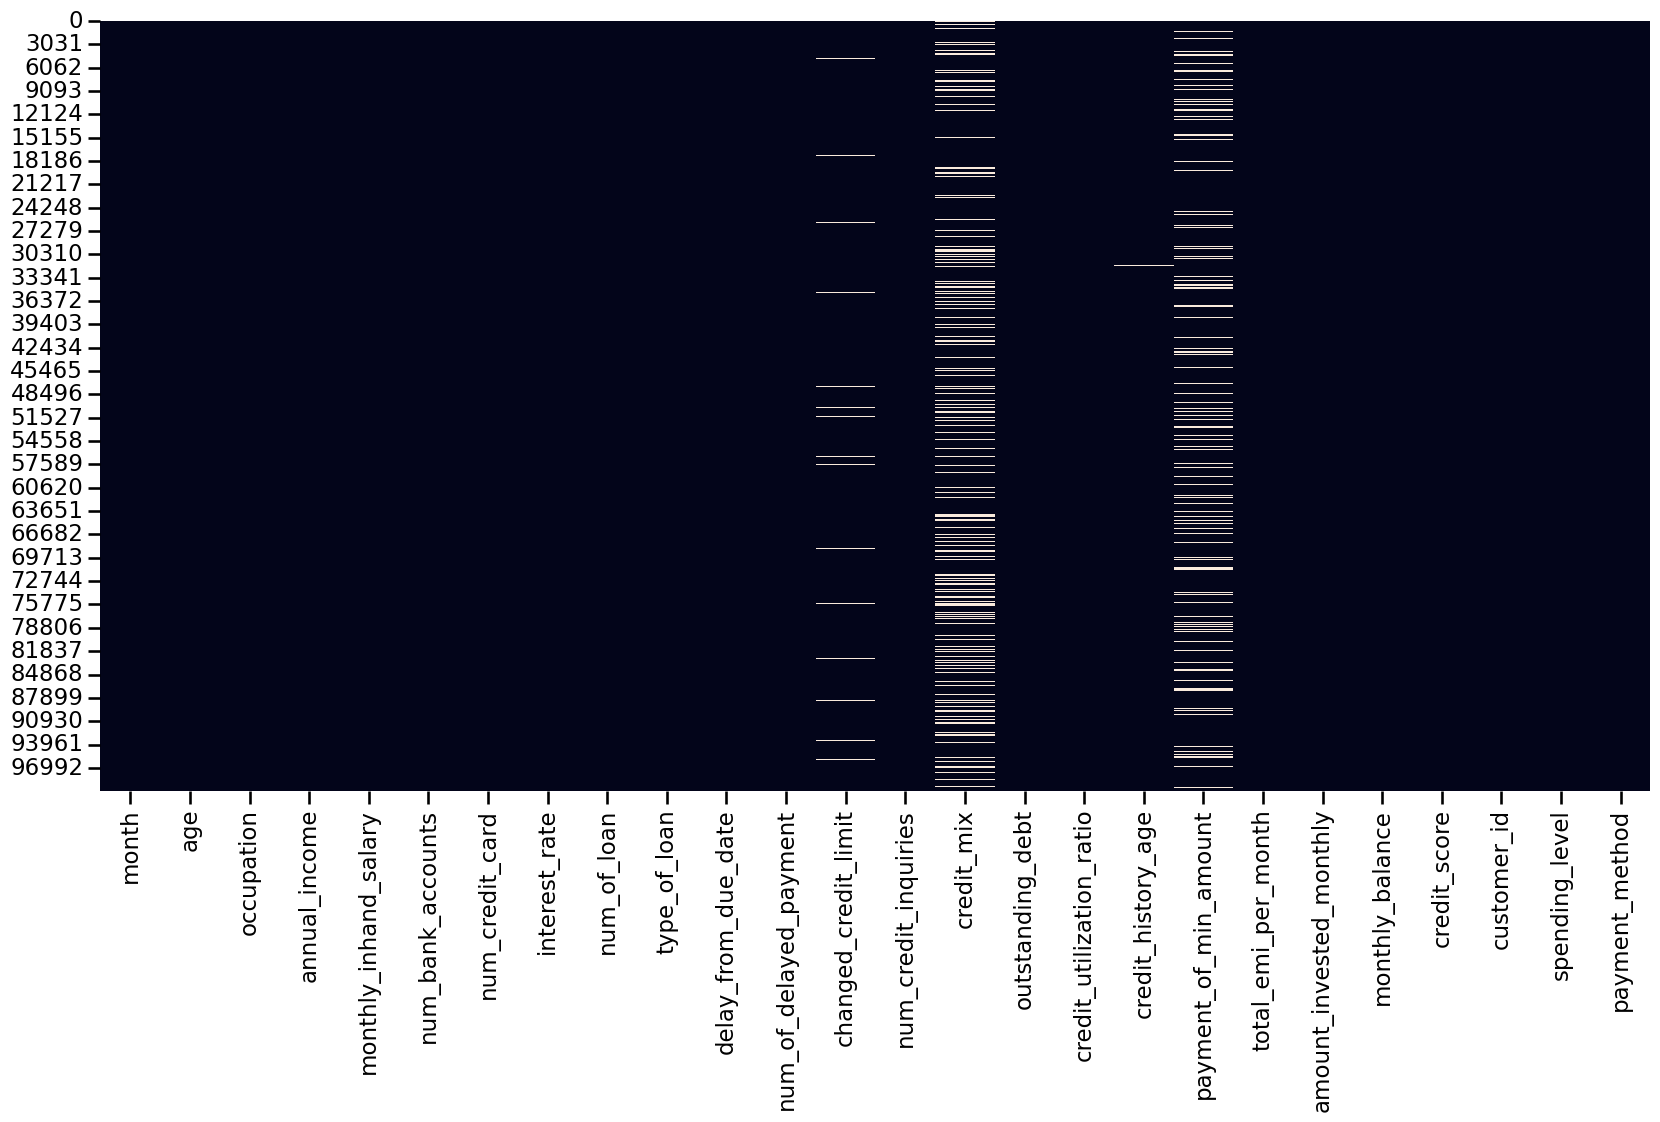

In [198]:
plt.figure(figsize = (20,10))
sns.heatmap(df.isnull(), cbar = False)
plt.show()

# Null values in payment of min amount

In [199]:
# 1. Create 10 debt brackets based on how much total debt they owe
df['debt_bracket'] = pd.qcut(df['outstanding_debt'].rank(method='first'), q=10, labels=False)

# 2. Fill the NaNs using the most common text category (mode) within each debt bracket
df['payment_of_min_amount'] = df.groupby('debt_bracket')['payment_of_min_amount'].transform(
    lambda x: x.fillna(x.mode()[0] if not x.mode().empty else 'Yes')
)

# 3. Drop the temporary debt bracket column
df = df.drop(columns=['debt_bracket'])

# 4. Encoding the columns
# Yes (paid minimum) -> 1, No (missed minimum) -> 0
df['payment_of_min_amount'] = df['payment_of_min_amount'].map({'Yes': 1, 'No': 0})

# Null values in changed credit limit

In [200]:
# Creating 10 income brackets to group similar financial profiles
df['monthly_income_q'] = pd.qcut(df['annual_income'], q=10, labels=False, duplicates='drop')

# Imputing limit changes using the median of people in the same income tier
df['changed_credit_limit'] = df.groupby('monthly_income_q')['changed_credit_limit'].transform(lambda x: x.fillna(x.median()))

# Dropping the temporary income tier column
df = df.drop(columns=['monthly_income_q'])

# Final safety sweep (filling edge cases with global median if an income bracket is somehow empty)
df['changed_credit_limit'] = df['changed_credit_limit'].fillna(df['changed_credit_limit'].median())

# Null values in credit mix

In [201]:
# Filling missing ratings using mode of people with the same card count
df['credit_mix'] = df.groupby('num_credit_card')['credit_mix'].transform(
    lambda x: x.fillna(x.mode()[0] if not x.mode().empty else 'Standard'))

# Encoding the columns
df['credit_mix'] = df['credit_mix'].map({'Bad': 0, 'Standard': 1, 'Good': 2})

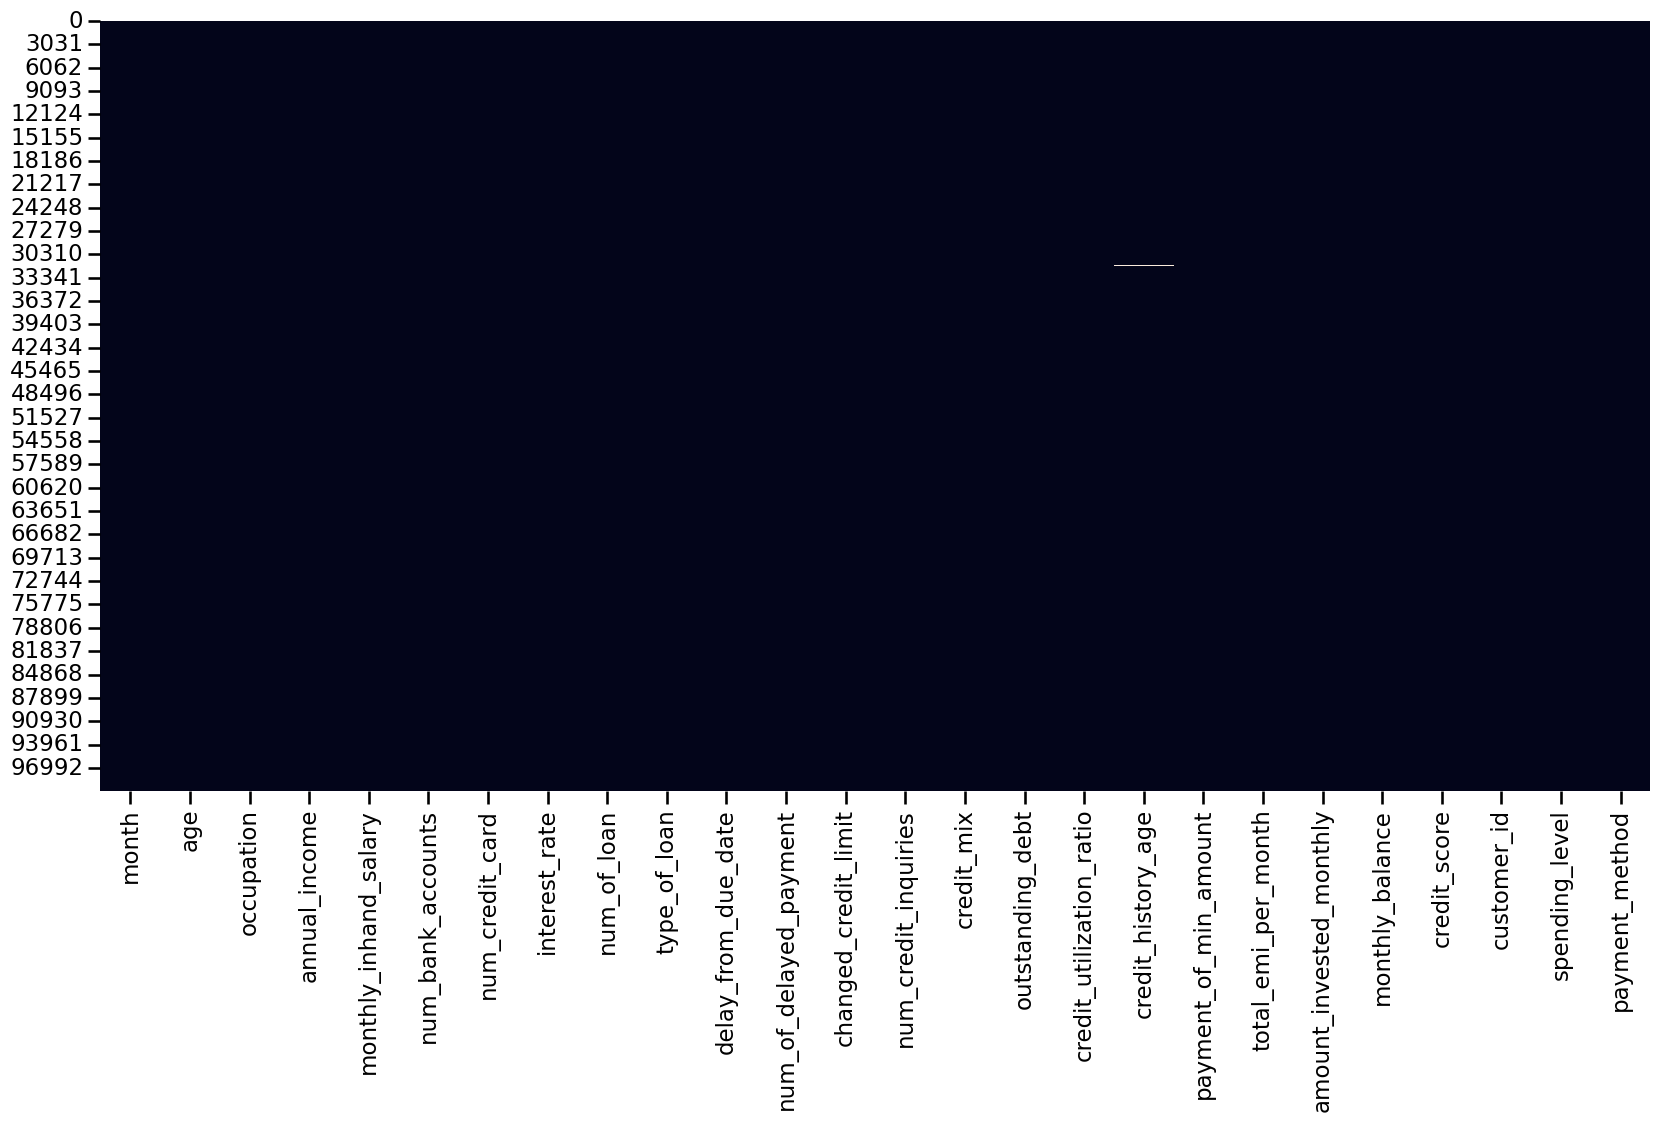

In [202]:
plt.figure(figsize = (20,10))
sns.heatmap(df.isnull(), cbar = False)
plt.show()

In [203]:
df.isnull().sum()

,0
month,0
age,0
occupation,0
annual_income,0
monthly_inhand_salary,0
num_bank_accounts,21
num_credit_card,0
interest_rate,0
num_of_loan,0
type_of_loan,0


In [204]:
df = df.dropna(subset = ['credit_history_age', 'num_bank_accounts', 'num_of_delayed_payment'])

All the null values have been treated

# Cleaning type of loan feature

In [205]:
# Filling missing loan values with a placeholder value so string functions don't crash
df['type_of_loan'] = df['type_of_loan'].fillna('No Loan').astype(str)

# Cleaning the string text by removing common noise words like 'and' and extra spaces
df['type_of_loan'] = (
    df['type_of_loan']
    .str.replace(r'\band\b', '', regex=True) # Removes the word 'and' cleanly
    .str.replace(r'\s*,\s*', ',', regex=True) # Standardizes spacing around commas
    .str.strip()
)

# Using Pandas vectorized string get_dummies to separate by comma and binarize instantly. This automatically handles the overlapping multi-label categories per row
loan_dummies = df['type_of_loan'].str.get_dummies(sep=',')

# Cleaning up the resulting dummy column headers to make them neat
loan_dummies.columns = [
    'loan_' + col.lower().replace(' ', '_').strip('_')
    for col in loan_dummies.columns
]

# Droping fallback or noise categories if they appear in the new dummy dataframe
cols_to_drop = ['loan_no_loan', 'loan_']
loan_dummies = loan_dummies.drop(columns=[c for c in cols_to_drop if c in loan_dummies.columns])

# Merge the new loan binary dummy columns back into the main working dataframe
df = pd.concat([df, loan_dummies], axis=1)

# Safely drop the original messy text column
df = df.drop(columns=['type_of_loan'])

# Treating Outliers

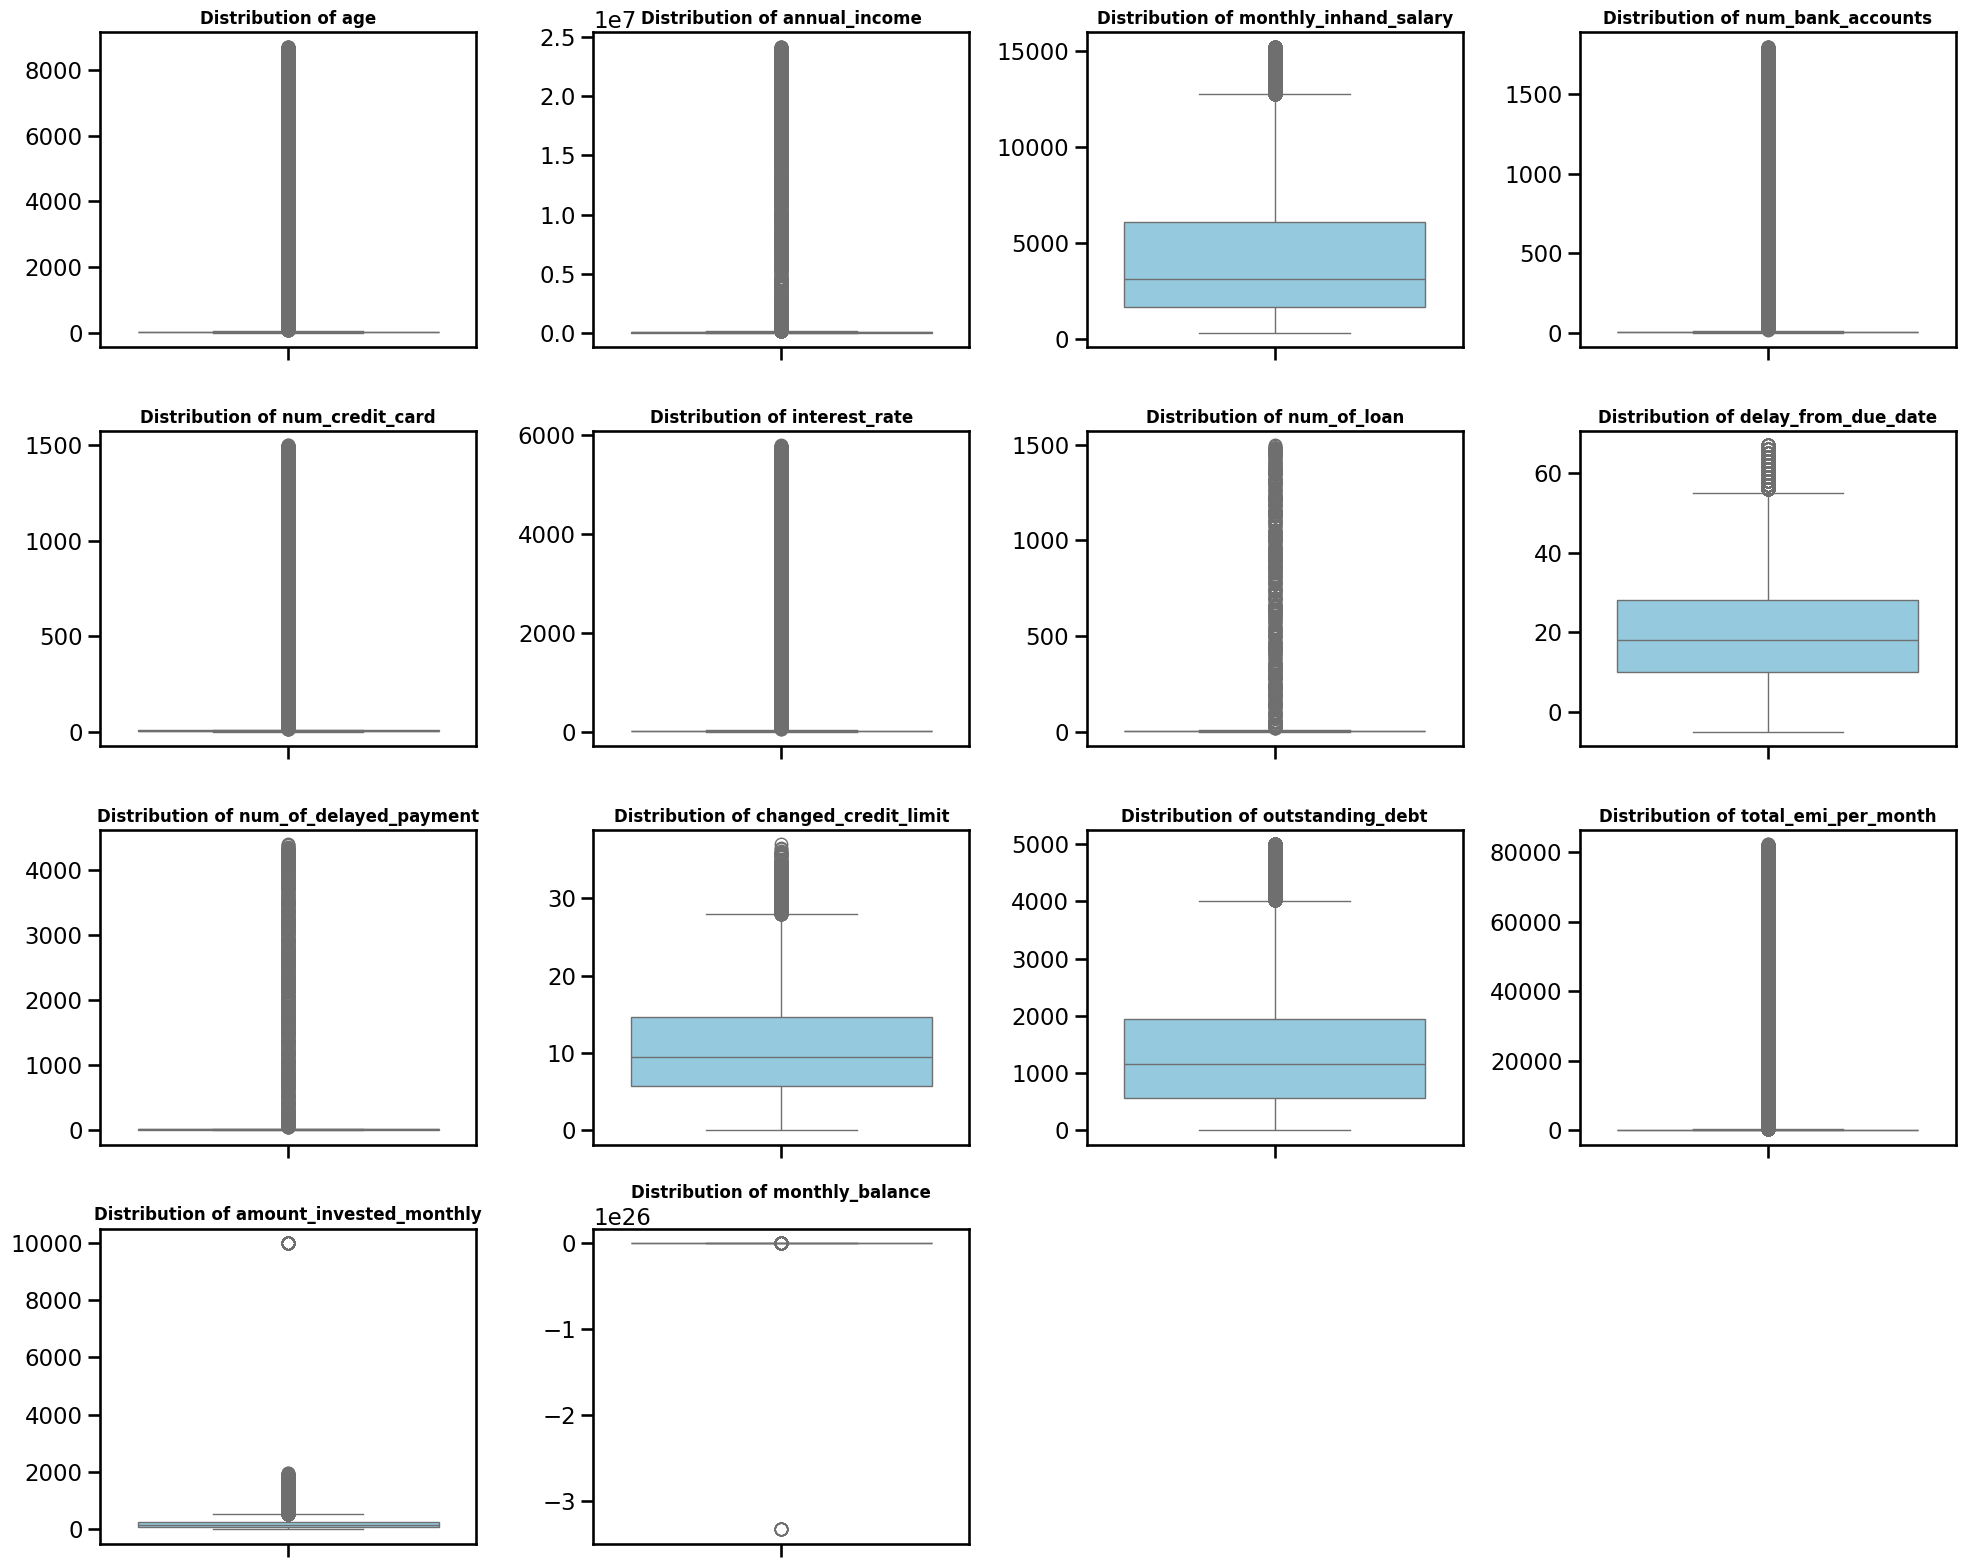

In [206]:
# Isolating the numeric columns we want to inspect for outliers
numeric_cols = [
    'age', 'annual_income', 'monthly_inhand_salary', 'num_bank_accounts',
    'num_credit_card', 'interest_rate', 'num_of_loan', 'delay_from_due_date',
    'num_of_delayed_payment', 'changed_credit_limit', 'outstanding_debt',
    'total_emi_per_month', 'amount_invested_monthly', 'monthly_balance'
]

# Ensuring we only plot columns that actually exist in working dataframe
num_cols_to_plot = [col for col in numeric_cols if col in df.columns]

# Setting up a grid layout (e.g. 4 rows and 4 columns)
num_features = len(num_cols_to_plot)
rows = (num_features // 4) + (1 if num_features % 4 != 0 else 0)

plt.figure(figsize=(20, rows * 4)) # Adaptive sizing based on features

# Looping through columns and draw a boxplot for each one
for i, col in enumerate(num_cols_to_plot):
    plt.subplot(rows, 4, i + 1)
    sns.boxplot(y=df[col], color='skyblue')
    plt.title(f'Distribution of {col}', fontsize=12, fontweight='bold')
    plt.ylabel('') # Hides messy axis labels
    plt.tight_layout()

plt.show()

# Transforming the dataset to treat Outliers

In [207]:
from sklearn.preprocessing import PowerTransformer, StandardScaler

In [208]:
# numerical features
features = [
    'age', 'annual_income', 'monthly_inhand_salary', 'num_bank_accounts',
    'num_credit_card', 'interest_rate', 'num_of_loan', 'delay_from_due_date',
    'num_of_delayed_payment', 'changed_credit_limit', 'outstanding_debt',
    'total_emi_per_month', 'amount_invested_monthly', 'monthly_balance'
]

In [209]:
 # Human Age limits
df['age'] = df['age'].clip(lower=18, upper=90)

# Financial Accounts & Cards (Capping extreme 1,500+ glitches)
df['num_bank_accounts'] = df['num_bank_accounts'].clip(lower=0, upper=15)
df['num_credit_card'] = df['num_credit_card'].clip(lower=0, upper=15)

# Loan counts and delayed metrics
df['num_of_loan'] = df['num_of_loan'].clip(lower=0, upper=15)
df['num_of_delayed_payment'] = df['num_of_delayed_payment'].clip(lower=0, upper=30)
df['delay_from_due_date'] = df['delay_from_due_date'].clip(lower=0, upper=60)

# Interest Rates (Capping the 6,000% errors)
df['interest_rate'] = df['interest_rate'].clip(lower=0, upper=40)

In [210]:
# The 1e26 Monthly Balance Glitch. Because 1e26 is so large, standard clipping needs a reliable upper bound. We clip at a very safe 95th percentile of the logical data range.
balance_upper = df.loc[df['monthly_balance'] < 1e10, 'monthly_balance'].quantile(0.95)
df['monthly_balance'] = df['monthly_balance'].clip(lower=-2000, upper=balance_upper)

In [211]:
pt = PowerTransformer(method='yeo-johnson', standardize=True)

# Transform ALL columns together to ensure consistency
df[features] = pt.fit_transform(df[features])

Building a histplot again



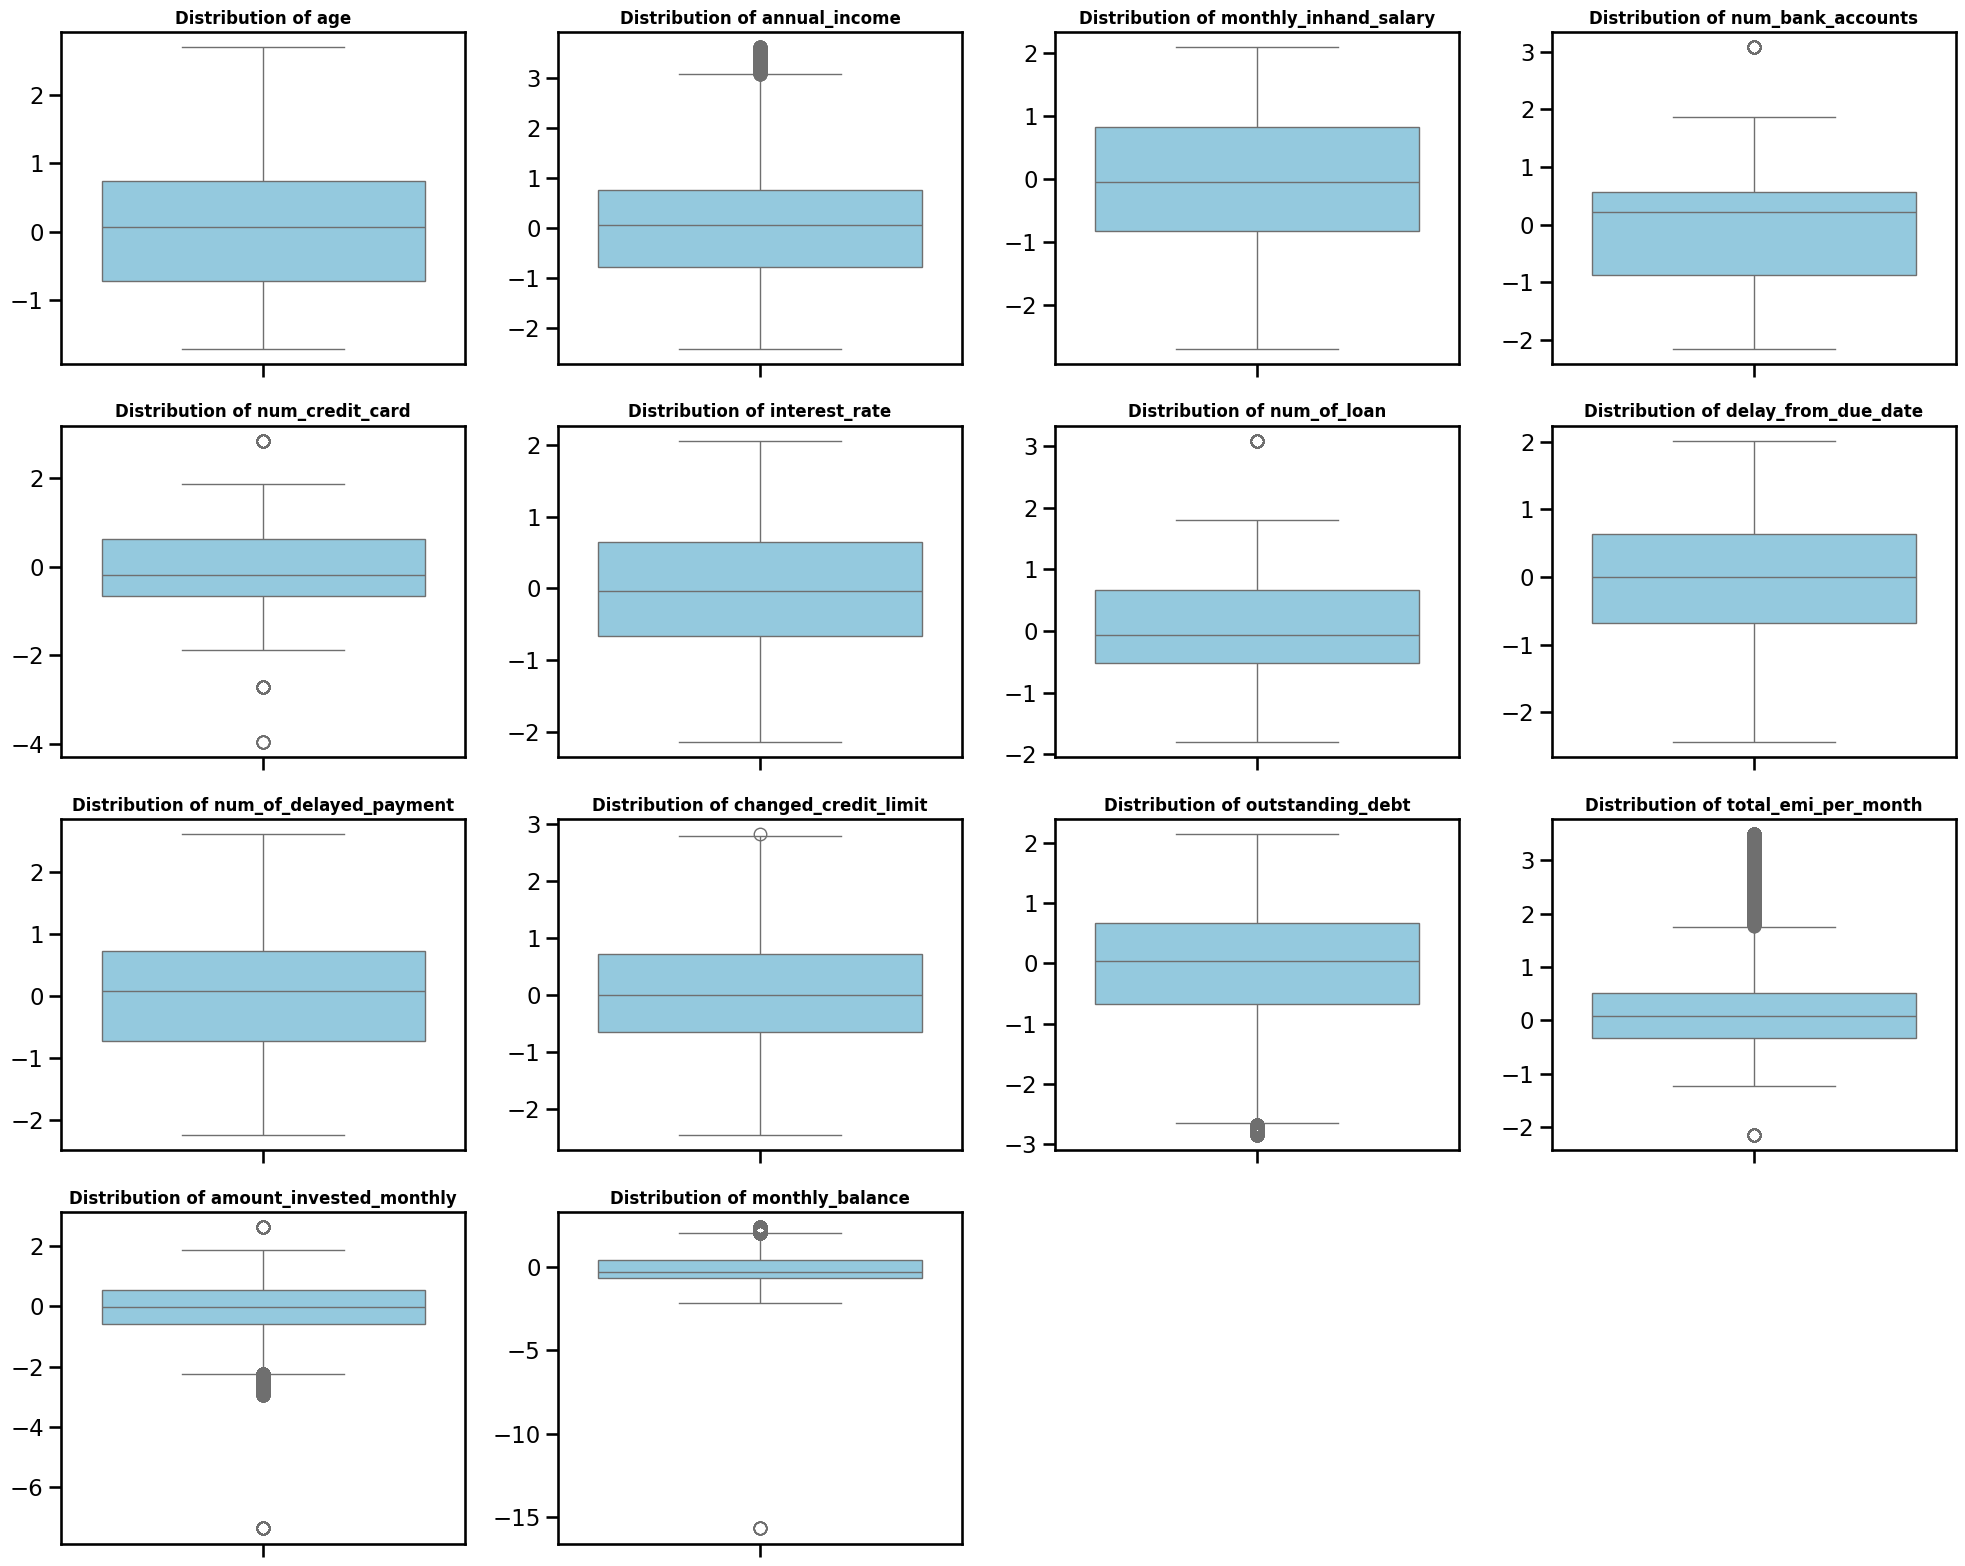

In [212]:

numeric_cols = [
    'age', 'annual_income', 'monthly_inhand_salary', 'num_bank_accounts',
    'num_credit_card', 'interest_rate', 'num_of_loan', 'delay_from_due_date',
    'num_of_delayed_payment', 'changed_credit_limit', 'outstanding_debt',
    'total_emi_per_month', 'amount_invested_monthly', 'monthly_balance'
]


num_cols_to_plot = [col for col in numeric_cols if col in df.columns]

num_features = len(num_cols_to_plot)
rows = (num_features // 4) + (1 if num_features % 4 != 0 else 0)

plt.figure(figsize=(20, rows * 4))


for i, col in enumerate(num_cols_to_plot):
    plt.subplot(rows, 4, i + 1)
    sns.boxplot(y=df[col], color='skyblue')
    plt.title(f'Distribution of {col}', fontsize=12, fontweight='bold')
    plt.ylabel('')
    plt.tight_layout()


plt.show()

The outliers have been treated

# Customers' monthly balances change chart

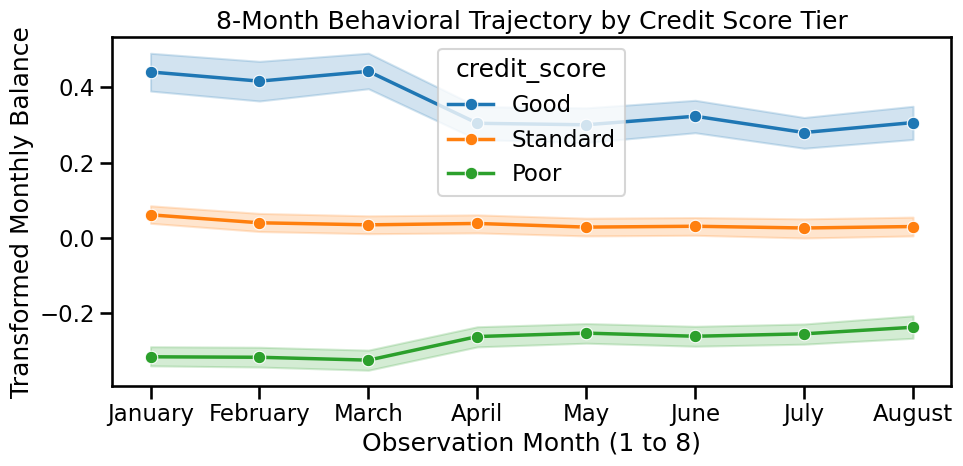

In [213]:
plt.figure(figsize=(10, 5))
sns.set_context("talk")
# Plots the mean and confidence intervals of all customers grouped by score across the 8 months
sns.lineplot(data=df, x='month', y='monthly_balance', hue='credit_score', marker='o', linewidth=2.5)
plt.title('8-Month Behavioral Trajectory by Credit Score Tier')
plt.xlabel('Observation Month (1 to 8)')
plt.ylabel('Transformed Monthly Balance')
plt.tight_layout()
plt.show()

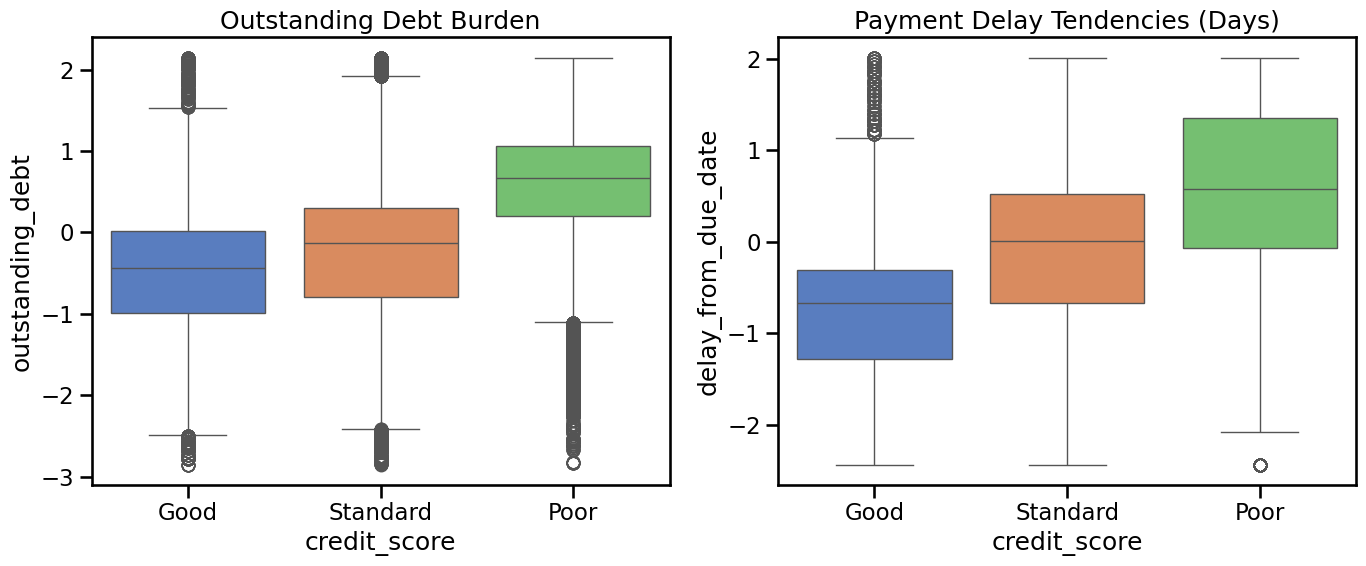

In [214]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
sns.boxplot(data=df, x='credit_score', y='outstanding_debt', ax=axes[0], palette='muted')
axes[0].set_title('Outstanding Debt Burden')

sns.boxplot(data=df, x='credit_score', y='delay_from_due_date', ax=axes[1], palette='muted')
axes[1].set_title('Payment Delay Tendencies (Days)')
plt.tight_layout()
plt.show()

Both outstanding debt and payment delays show a strong monotonic relationship with the final credit score tier.The distinct vertical separation between the blue (Good) and green (Poor) boxes guarantees high feature importance scores in our upcoming models.



In [215]:
df.columns

Index(['month', 'age', 'occupation', 'annual_income', 'monthly_inhand_salary',
       'num_bank_accounts', 'num_credit_card', 'interest_rate', 'num_of_loan',
       'delay_from_due_date', 'num_of_delayed_payment', 'changed_credit_limit',
       'num_credit_inquiries', 'credit_mix', 'outstanding_debt',
       'credit_utilization_ratio', 'credit_history_age',
       'payment_of_min_amount', 'total_emi_per_month',
       'amount_invested_monthly', 'monthly_balance', 'credit_score',
       'customer_id', 'spending_level', 'payment_method', 'loan_auto_loan',
       'loan_credit-builder_loan', 'loan_debt_consolidation_loan',
       'loan_home_equity_loan', 'loan_mortgage_loan', 'loan_not_specified',
       'loan_payday_loan', 'loan_personal_loan', 'loan_student_loan'],
      dtype='object')

In [216]:
df = df.drop(columns = ['customer_id'])

# Encoding columns for model

# 1. Month

In [217]:
df['month'].unique()

array(['January', 'February', 'March', 'April', 'May', 'June', 'July',
       'August'], dtype=object)

In [218]:
df['month'] = df['month'].map({'January': 1, 'February' : 2, 'March' : 3, 'April' : 4, 'May': 5, 'June': 6, 'July': 7, 'August': 8})

# 2. Occupation

In [219]:
df['occupation'].unique()

array(['Scientist', 'unemployed', 'Teacher', 'Engineer', 'Entrepreneur',
       'Developer', 'Lawyer', 'Media_Manager', 'Doctor', 'Journalist',
       'Manager', 'Accountant', 'Musician', 'Mechanic', 'Writer',
       'Architect'], dtype=object)

Categorizing the columns based on streams, i.e. Science, commerce, arts etc. Then encoding the professions based on these categories

In [220]:
education_type = {'Scientist': 'science', 'unemployed': 'unemployed', 'Teacher': 'arts', 'Engineer': 'science', 'Entrepreneur': 'science',
       'Developer': 'science', 'Lawyer' : 'commerce', 'Media_Manager': 'commerce', 'Doctor' :'science', 'Journalist': 'arts',
       'Manager':'commerce', 'Accountant': 'commerce', 'Musician': 'arts', 'Mechanic': 'science', 'Writer' : 'arts',
       'Architect' : 'science'}

In [221]:
df['occupation'] = df['occupation'].map(education_type)

In [222]:
df['occupation'].unique()

array(['science', 'unemployed', 'arts', 'commerce'], dtype=object)

In [223]:
df['occupation'] = df['occupation'].map({'unemployed': 0, 'science' : 1, 'commerce' : 2, 'arts' :3})

# 3. credit_score

In [224]:
df['credit_score'].unique()

array(['Good', 'Standard', 'Poor'], dtype=object)

In [225]:
df['credit_score'] = df['credit_score'].map({'Good' : 1, 'Standard' : 2, 'Poor': 0})

In [226]:
df['credit_score'].unique()

array([1, 2, 0])

# 4. spending level

In [227]:
df['spending_level'].unique()

array(['high', 'low'], dtype=object)

In [228]:
df['spending_level'] = df['spending_level'].map({'high': 1, 'low' : 0})

In [229]:
df['spending_level'].unique()

array([1, 0])

# 5. payment_method

In [230]:
df['payment_method'].unique()

array(['Small_value_payments', 'Large_value_payments',
       'Medium_value_payments'], dtype=object)

In [231]:
cat_col = ['payment_method']
df = pd.get_dummies(df, columns = cat_col, drop_first = True, dtype = int)

In [232]:
df.head(5)

,month,age,occupation,annual_income,monthly_inhand_salary,num_bank_accounts,num_credit_card,interest_rate,num_of_loan,delay_from_due_date,num_of_delayed_payment,changed_credit_limit,num_credit_inquiries,credit_mix,outstanding_debt,credit_utilization_ratio,credit_history_age,payment_of_min_amount,total_emi_per_month,amount_invested_monthly,monthly_balance,credit_score,spending_level,loan_auto_loan,loan_credit-builder_loan,loan_debt_consolidation_loan,loan_home_equity_loan,loan_mortgage_loan,loan_not_specified,loan_payday_loan,loan_personal_loan,loan_student_loan,payment_method_Medium_value_payments,payment_method_Small_value_payments
0,1,-0.965485,1,-0.798368,-0.695261,-0.870034,-0.666496,-1.570517,0.32519,-1.614057,-1.056253,0.273414,4.0,1,-0.339373,26.822620,265.0,0,-0.075875,-0.519695,-0.436953,1,1,1,1,0,1,0,0,0,1,0,0,1
1,2,-0.965485,1,-0.798368,-0.833648,-0.870034,-0.666496,-1.570517,0.32519,-2.439165,-0.400417,0.273414,4.0,2,-0.339373,31.944960,263.0,0,-0.075875,-0.151741,-0.584775,1,0,1,1,0,1,0,0,0,1,0,0,0
2,3,-0.965485,1,-0.798368,-0.833648,-0.870034,-0.666496,-1.570517,0.32519,-1.614057,-1.056253,0.153118,4.0,2,-0.339373,28.609352,267.0,0,-0.075875,-0.504088,-0.337817,1,0,1,1,0,1,0,0,0,1,0,1,0
3,4,-0.965485,1,-0.798368,-0.833648,-0.870034,-0.666496,-1.570517,0.32519,-1.279439,-1.557682,-0.555431,4.0,2,-0.339373,31.377862,268.0,0,-0.075875,0.307595,-0.910383,1,0,1,1,0,1,0,0,0,1,0,0,1
4,5,-0.965485,1,-0.798368,-0.695261,-0.870034,-0.666496,-1.570517,0.32519,-1.138213,-0.400417,0.273414,4.0,2,-0.339373,24.797347,269.0,0,-0.075875,-1.212698,-0.283416,1,1,1,1,0,1,0,0,0,1,0,1,0


#Dividing the features between independant and dependant variables.

In [233]:
x = df.iloc[:, df.columns != 'credit_score']
y = df.iloc[:, df.columns == 'credit_score']

In [234]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.3, random_state = 42)

# Model building

In [235]:
def get_test_report(model):
  y_pred = model.predict(x_test)
  return classification_report(y_test, y_pred)

In [236]:
linear_reg = LinearRegression()
linear_reg.fit(x_train, y_train)

LinearRegression()

In [237]:
y_pred = linear_reg.predict(x_test)

In [238]:
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)

print(f"Mean Squared Error: {mse:.4f}")
print(f"Root Mean Squared Error: {rmse:.4f}")

Mean Squared Error: 0.6561
Root Mean Squared Error: 0.8100


# Logistic Regression

In [239]:
log_reg = LogisticRegression()
log_reg.fit(x_train, y_train)

LogisticRegression()

In [240]:
y_pred = log_reg.predict(x_test)

In [241]:
print(get_test_report(log_reg))

              precision    recall  f1-score   support

           0       0.64      0.46      0.53      8632
           1       0.53      0.40      0.45      5352
           2       0.63      0.78      0.69     15989

    accuracy                           0.62     29973
   macro avg       0.60      0.54      0.56     29973
weighted avg       0.61      0.62      0.60     29973



In [242]:
y_proba = log_reg.predict_proba(x_test)
roc_auc_score(y_test, y_proba, multi_class="ovr", average="macro")

np.float64(0.7742162502725122)

In [243]:
xgb_model = XGBClassifier(
    n_estimators=150,
    max_depth=8,
    learning_rate=0.1,
    objective='multi:softprob',  # tells XGBoost it's a multiclass assignment problem
    random_state=42,
    n_jobs=-1 # tells the library to utilize all available CPU cores
)

In [244]:
xgb_model.fit(x_train, y_train)

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric=None, feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=0.1, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=8,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=150,
              n_jobs=-1, num_parallel_tree=None, ...)

In [245]:
print(get_test_report(xgb_model))

              precision    recall  f1-score   support

           0       0.76      0.74      0.75      8632
           1       0.68      0.69      0.69      5352
           2       0.78      0.79      0.79     15989

    accuracy                           0.76     29973
   macro avg       0.74      0.74      0.74     29973
weighted avg       0.76      0.76      0.76     29973



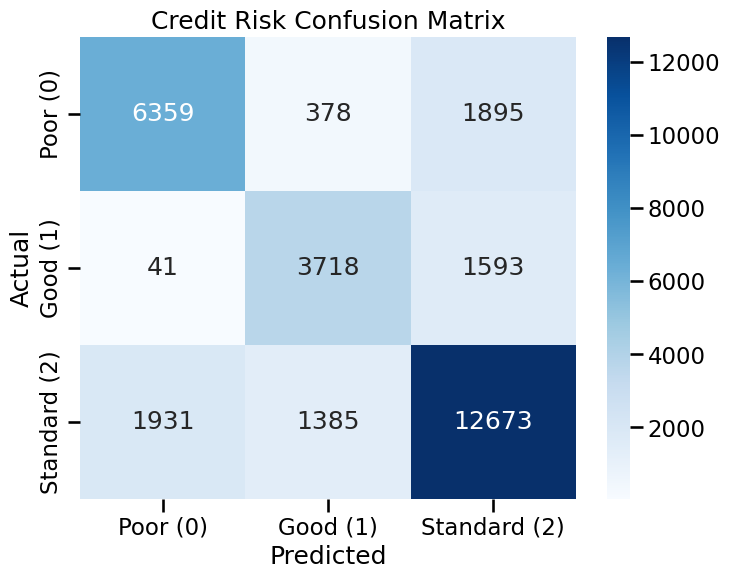

In [246]:
y_pred = xgb_model.predict(x_test)
cm = confusion_matrix(y_test, y_pred)

# Plotting the confusion matrix
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Poor (0)', 'Good (1)', 'Standard (2)'],
            yticklabels=['Poor (0)', 'Good (1)', 'Standard (2)'])
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.title('Credit Risk Confusion Matrix')
plt.show()

In [247]:
y_proba = xgb_model.predict_proba(x_test)
roc_auc_score(y_test, y_proba, multi_class="ovr", average="macro")

np.float64(0.8984852869901844)

In [248]:
from sklearn.model_selection import RandomizedSearchCV
from sklearn.utils.class_weight import compute_sample_weight

In [249]:
# Computing class weights to address the imbalance. This ensures the search evaluates minority classes fairly
sample_weights = compute_sample_weight(class_weight='balanced', y=y_train)

In [250]:
# Defining the base estimator
xgb_clf = xgb.XGBClassifier(
    objective='multi:softprob',
    num_class=3,
    random_state=42,
    n_jobs=-1
)

In [251]:
# hyper parameter tuning
param_dist = {
    'n_estimators': [100, 200, 300],
    'learning_rate': [0.03, 0.05, 0.1],
    'max_depth': [4, 6, 8],              # Controls how complex the trees get
    'min_child_weight': [1, 3, 5, 7],    # Higher numbers prevent overfitting majority class
    'subsample': [0.7, 0.8, 0.9],         # Row subsampling to add variance
    'colsample_bytree': [0.7, 0.8, 0.9],  # Column subsampling per tree
    'gamma': [0, 0.1, 0.3, 0.5]          # Minimum loss reduction required to split
}

In [252]:
# Initializing RandomizedSearch
# Using f1_macro so that the metric penalizes ignoring 'Good' or 'Poor'
random_search = RandomizedSearchCV(
    estimator=xgb_clf,
    param_distributions=param_dist,
    n_iter=15,             # Number of random parameter combinations to try
    scoring='f1_macro',    # The target metric to optimize
    cv=3,                  # 3-Fold cross-validation
    verbose=2,
    random_state=42,
    n_jobs=-1
)

In [253]:
print("Starting hyperparameter tuning...")
random_search.fit(x_train, y_train, sample_weight=sample_weights)

Starting hyperparameter tuning...
Fitting 3 folds for each of 15 candidates, totalling 45 fits


RandomizedSearchCV(cv=3,
                   estimator=XGBClassifier(base_score=None, booster=None,
                                           callbacks=None,
                                           colsample_bylevel=None,
                                           colsample_bynode=None,
                                           colsample_bytree=None, device=None,
                                           early_stopping_rounds=None,
                                           enable_categorical=True,
                                           eval_metric=None, feature_types=None,
                                           feature_weights=None, gamma=None,
                                           grow_policy=None,
                                           importance_type=None,
                                           interaction_constraint...
                                           monotone_constraints=None,
                                           multi_strategy=None,
                                           n_estimators=None, n_jobs=-1,
                                           num_class=3, ...),
                   n_iter=15, n_jobs=-1,
                   param_distributions={'colsample_bytree': [0.7, 0.8, 0.9],
                                        'gamma': [0, 0.1, 0.3, 0.5],
                                        'learning_rate': [0.03, 0.05, 0.1],
                                        'max_depth': [4, 6, 8],
                                        'min_child_weight': [1, 3, 5, 7],
                                        'n_estimators': [100, 200, 300],
                                        'subsample': [0.7, 0.8, 0.9]},
                   random_state=42, scoring='f1_macro', verbose=2)

In [254]:
# viewing best parameteres and f1 score
print("\nBest Hyperparameters Found:")
print(random_search.best_params_)

print(f"\nBest Cross-Validation Macro F1-Score: {random_search.best_score_:.4f}")


Best Hyperparameters Found:
{'subsample': 0.8, 'n_estimators': 300, 'min_child_weight': 7, 'max_depth': 8, 'learning_rate': 0.1, 'gamma': 0.5, 'colsample_bytree': 0.7}

Best Cross-Validation Macro F1-Score: 0.7511


# RNN model

In [255]:
# Isolating feature columns (excluding metadata and target)
exclude_cols = ['month', 'credit_score']
feature_cols = [col for col in df.columns if col not in exclude_cols]

# Slicing the dataframe to fit perfect 8-month customer sequence blocks
time_steps = 8
total_features = len(feature_cols)
total_customers = len(df) // time_steps
perfect_row_count = total_customers * time_steps

df_perfect = df.iloc[:perfect_row_count].copy()

In [256]:
# Applying Standard Scaling to the features
scaler = StandardScaler()
df_perfect[feature_cols] = scaler.fit_transform(df_perfect[feature_cols])

# Extracting target (August credit score - every 8th row starting at index 7)
y_rnn = df_perfect['credit_score'].values[7::8]

In [257]:
# Reshaping the scaled features into 3D structure: (Customers, Months, Features)
X_rnn = df_perfect[feature_cols].values.reshape(total_customers, time_steps, total_features)


print("Scaled Features Shape (X_rnn):", X_rnn.shape)  # Expecting (12488, 8, 32)
print("Target Shape (y_rnn):", y_rnn.shape)            # Expecting (12488,)

Scaled Features Shape (X_rnn): (12488, 8, 32)
Target Shape (y_rnn): (12488,)


In [258]:
# Splitting into 80% training and 20% testing using unique sequential names
X_train_seq, X_test_seq, y_train_seq, y_test_seq = train_test_split(
    X_rnn, y_rnn, test_size=0.2, random_state=42, stratify=y_rnn
)

In [259]:
from sklearn.utils.class_weight import compute_class_weight
# Computing class weights so that the model pays equal attention to Poor, Good, and Standard
class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(y_train_seq),
    y=y_train_seq
)
class_weight_dict = dict(enumerate(class_weights))

print("Train split shapes:", X_train_seq.shape, y_train_seq.shape)
print("Class weights applied:", class_weight_dict)

Train split shapes: (9990, 8, 32) (9990,)
Class weights applied: {0: np.float64(1.1490683229813665), 1: np.float64(1.8479467258601554), 2: np.float64(0.6294896030245747)}


In [260]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import GRU, Dense, Dropout

model_rnn = Sequential([
    # Processing the clean scaled sequence through a GRU layer
    GRU(48, input_shape=(X_train_seq.shape[1], X_train_seq.shape[2]), return_sequences=False),
    Dropout(0.3),

    # Simple classification layer mapping to Poor (0), Good (1), Standard (2)
    Dense(3, activation='softmax')
])

# Compiling the model
model_rnn.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model_rnn.summary()

# Training the model
history = model_rnn.fit(
    X_train_seq, y_train_seq,
    validation_data=(X_test_seq, y_test_seq),
    epochs=25,
    batch_size=64,
    class_weight=class_weight_dict,
    verbose=1
)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ gru (GRU)                       │ (None, 48)             │        11,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 48)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 3)              │           147 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,955 (46.70 KB)

 Trainable params: 11,955 (46.70 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/25
157/157 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.4853 - loss: 0.9452 - val_accuracy: 0.5677 - val_loss: 0.9223
Epoch 2/25
157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.5688 - loss: 0.8495 - val_accuracy: 0.5777 - val_loss: 0.9172
Epoch 3/25
157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.5934 - loss: 0.8182 - val_accuracy: 0.5993 - val_loss: 0.8689
Epoch 4/25
157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.6071 - loss: 0.8066 - val_accuracy: 0.6117 - val_loss: 0.8635
Epoch 5/25
157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.6215 - loss: 0.7960 - val_accuracy: 0.6137 - val_loss: 0.8736
Epoch 6/25
157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.6292 - loss: 0.7825 - val_accuracy: 0.6181 - val_loss: 0.8560
Epoch 7/25
157/157 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - accuracy: 0.6348 - loss: 0.7765 - val_accuracy: 0.6161 - val_loss: 0.8642
Epoch 8/25
157/157 ━━━━━━━━━━━━━━━━━━━━ 3s 17ms/step - accuracy: 0.6324 - loss: 0.7657 - val_accuracy:

There is overfitting because training accuracy is 69% but testing accuracy is 61%. The validation loss is 88%. The network is memorizing some noise

# Conclusion

Xgboost model is performing the best